In [1]:
import tensorflow as tf 
from tensorflow.keras import datasets,layers,models 
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.metrics import classification_report

I0000 00:00:1791274700.466482    5573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791274700.468578    5573 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791274700.859824    5573 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791274702.215958    5573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
(xtrain,ytrain),(xtest,ytest) = datasets.cifar10.load_data()

In [3]:
xtrain.shape

(50000, 32, 32, 3)

In [4]:
xtest.shape

(10000, 32, 32, 3)

In [5]:
classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','shi p','truck']

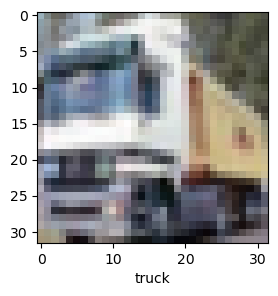

In [10]:
def plot_sample(x, y, index):
    plt.figure(figsize=(3, 3))
    plt.imshow(x[index])
    plt.xlabel(classes[y[index][0]])
    plt.show()

plot_sample(xtrain, ytrain, 1)


In [11]:
xtrain = xtrain/255 
xtest = xtest/255

In [14]:
cnn = models.Sequential([   
        layers.Conv2D(filters=32,activation='relu',kernel_size = (3,3),input_shape=(32,32,3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(filters=64,activation='relu',kernel_size = (3,3),input_shape =(32,32,3)),
        layers.MaxPooling2D((2,2)), 
        layers.Flatten(),  
        layers.Dense(64,activation='relu'),  
        layers.Dense(10,activation='softmax')
]) 
cnn.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']) 
cnn.fit(xtrain,ytrain,epochs=20)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.4639 - loss: 1.4987
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6054 - loss: 1.1312
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6510 - loss: 1.0028
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6801 - loss: 0.9186
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7015 - loss: 0.8566
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7199 - loss: 0.8048
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7347 - loss: 0.7612
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7496 - loss: 0.7177
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7631 - loss: 0.6811
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7735 - loss: 0.6487
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7847 - loss: 0.6207
Epoch 12/20
1563/1563 ━━━━━━━━

In [15]:
ypred = cnn.predict(xtest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [16]:
cnn.evaluate(xtest,ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6859 - loss: 1.1453


[1.1452564001083374, 0.6858999729156494]

In [17]:
ytest=ytest.reshape(-1,)
ypred=cnn.predict(xtest)

yclasses=[np.argmax(element) for element in ypred]
print('classification report:\ n',classification_report(ytest,yclasses))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
classification report:\ n               precision    recall  f1-score   support

           0       0.77      0.71      0.74      1000
           1       0.79      0.79      0.79      1000
           2       0.48      0.66      0.56      1000
           3       0.53      0.45      0.49      1000
           4       0.70      0.58      0.63      1000
           5       0.65      0.54      0.59      1000
           6       0.66      0.83      0.73      1000
           7       0.83      0.67      0.74      1000
           8       0.81      0.82      0.82      1000
           9       0.71      0.82      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.69      0.68     10000
weighted avg       0.69      0.69      0.68     10000

